In [1]:
# ==============================================================================
# Import modules
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import datasets
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

<Axes: >

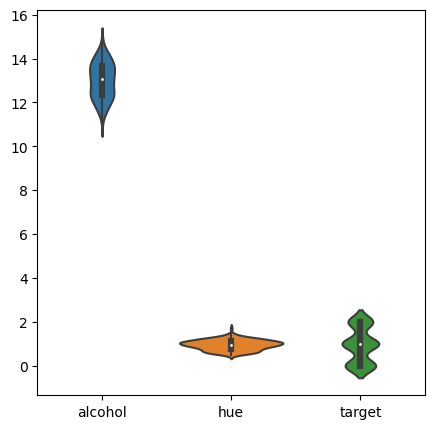

In [2]:
# ==============================================================================
# Load data and select features
# ==============================================================================
data = datasets.load_wine()
features = [0, 10]
X = data.data[:, features]
y = data.target
feature_names = [data.feature_names[i] for i in features]


# ==============================================================================
# Violin plot of input data to inspect distribution of features
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(5, 5))  # figure size 5x5
df = pd.DataFrame(X, columns=feature_names)  # data into a pandas  data frame
df["target"] = y  # target column
sns.violinplot(data=df, ax=ax)

In [3]:
# ==============================================================================
# Split into training and test data
# ==============================================================================

# Print lables of all classes in data set
print("Class labels:", np.unique(y))


# Split data into training and test data (60% training, 40% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=5, stratify=y)


# Show distribution of classes in input data, training data and test data
# Alternative 1
print(f"Labels counts in y: {np.bincount(y)}")
print(f"Labels counts in y_train: {np.bincount(y_train)}")
print(f"Labels counts in y_test: {np.bincount(y_test)}")
print()


# Show distribution of classes in input data, training data and test data
# Alternative 2
unique, counts = np.unique(y, return_counts=True)
print("Labels counts in y:", unique, counts)

unique, counts = np.unique(y_train, return_counts=True)
print("Labels counts in y_train:", unique, counts)

unique, counts = np.unique(y_test, return_counts=True)
print("Labels counts in y_test:", unique, counts)

Class labels: [0 1 2]
Labels counts in y: [59 71 48]
Labels counts in y_train: [35 42 29]
Labels counts in y_test: [24 29 19]

Labels counts in y: [0 1 2] [59 71 48]
Labels counts in y_train: [0 1 2] [35 42 29]
Labels counts in y_test: [0 1 2] [24 29 19]


Mean of X_train_sc: [-2.48333848e-15 -8.38951550e-16]
Stddev of X_train_sc: [1. 1.]
Mean of X_test_sc: [0.17533894 0.13801106]
Stddev of X_test_sc: [0.99923971 0.96693152]


<Axes: >

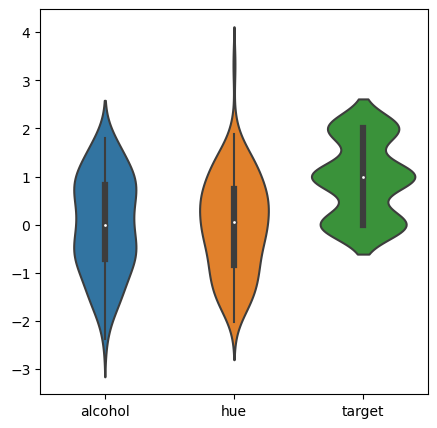

In [4]:
# ==============================================================================
# Scale features using StandardScaler class in scikit-learn
# ==============================================================================

# Initialise standard scaler and compute mean and STD from training data
sc = StandardScaler()
sc.fit(X_train)


# Transform (standardise) both X_train and X_test with mean and stddev from
# training data
X_train_sc = sc.transform(X_train)
X_test_sc = sc.transform(X_test)

print("Mean of X_train_sc:", np.mean(X_train_sc, axis=0))
print("Stddev of X_train_sc:", np.std(X_train_sc, axis=0))

# Print mean and stddev of X_test_sc (doesn't have to be exactly 0 and 1)
print("Mean of X_test_sc:", np.mean(X_test_sc, axis=0))
print("Stddev of X_test_sc:", np.std(X_test_sc, axis=0))

# Plot training data distributions after standardisation
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
df = pd.DataFrame(X_train_sc, columns=feature_names)
df["target"] = y_train
sns.violinplot(data=df, ax=ax)

In [5]:
# ==============================================================================
# Train a multiclass perceptron using scikit-learn
# ==============================================================================

# Initialise the model
ppn = Perceptron(max_iter=100, eta0=0.05, random_state=77)
ppn.fit(X_train_sc, y_train)

Perceptron(eta0=0.05, max_iter=100, random_state=77)

In [6]:
# ==============================================================================
# Make predictions for the test set
# ==============================================================================

# Predict classes for samples in test set and print number of misclassfications
y_pred = ppn.predict(X_test_sc)
print("Misclassified samples: {0}".format((y_test != y_pred).sum()))


# ==============================================================================
# Compute performance metrics
# ==============================================================================

# Variant I: Print accuracy computed from predictions on the test set
num_misclassified = (y_test != y_pred).sum()
print("Accuracy: {0:.2f}".format(1.0 - num_misclassified / len(y_test)))

# Variant II: Print accuracy computed from predictions on the test set
print("Accuracy: {0:.2f}".format(accuracy_score(y_test, y_pred)))

# Variant III: Print accuracy computed from predictions on the test set
# Score also internally calls predict on the test set and then compares the predictions
# so it does more than the above two variants
print("Accuracy: {0:.2f}".format(ppn.score(X_test_sc, y_test)))

Misclassified samples: 14
Accuracy: 0.81
Accuracy: 0.81
Accuracy: 0.81


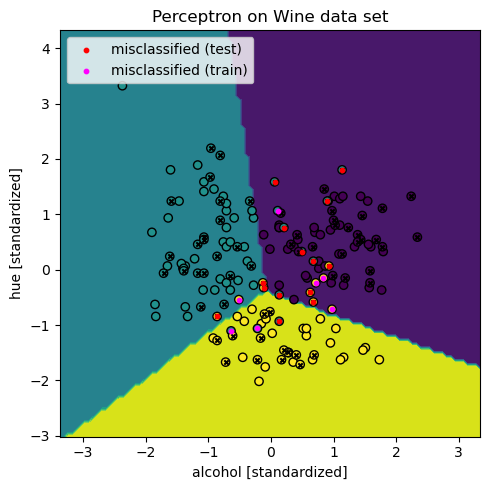

In [7]:
# ==============================================================================
# Plot results with plot function for decision regions using scikit-learn
# ==============================================================================

X_combined_sc = np.vstack((X_train_sc, X_test_sc))
y_combined = np.hstack((y_train, y_test))

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

plot = DecisionBoundaryDisplay.from_estimator(
    estimator=ppn,
    X=X_combined_sc,
    alpha=1.0,
    ax=ax,
    response_method="predict",
    xlabel=f"{feature_names[0]} [standardized]",
    ylabel=f"{feature_names[1]} [standardized]",
)

plot.ax_.scatter(X_combined_sc[:, 0], X_combined_sc[:, 1], c=y_combined, marker="o", edgecolor="k")

# Highlight test samples
plot.ax_.scatter(
    X_test_sc[:, 0],
    X_test_sc[:, 1],
    marker="x",
    s=10,
    c="k",
)

# Highlight misclassified test samples
plot.ax_.scatter(
    X_test_sc[y_test != y_pred, 0],
    X_test_sc[y_test != y_pred, 1],
    marker="o",
    s=10,
    c="r",
    facecolors="none",
    label="misclassified (test)",
)

# Highlight misclassified training samples
y_pred = ppn.predict(X_train_sc)
plot.ax_.scatter(
    X_train_sc[y_train != y_pred, 0],
    X_train_sc[y_train != y_pred, 1],
    marker="o",
    s=10,
    c="magenta",
    facecolors="none",
    label="misclassified (train)",
)

plt.legend(loc="upper left")
plt.title("Perceptron on Wine data set")
plt.tight_layout()
plt.show()

In [8]:
# =============================================================================
# Get weights, number of weight updates, number of iterations (epochs)
# =============================================================================

num_weight_updates = ppn.t_
nump_epochs = ppn.n_iter_

weights = ppn.coef_
bias = ppn.intercept_